# DP Plots

This notebook provides visualizations for the tradeoff between AUC and noise levels.

In [30]:
import pandas as pd
from matplotlib import pyplot as plt

In [31]:
filenames = [
    "../data/tables/summary_cluster_sepsis_ensemble_table_gaussian_fixed_t_max.csv",
]
df = pd.concat([pd.read_csv(filename, header=[0,1,2]) for filename in filenames])

df.head()

Unnamed: 0_level_0 Unnamed: 1_level_0 Unnamed: 2_level_0  \
  Unnamed: 0_level_1 Unnamed: 1_level_1 Unnamed: 2_level_1   
     N. Trajectories         Ensemble k   Ensemble epsilon   
0                500                 20                 30   
1                500                 20                100   
2                500                 20                300   
3                500                 20               1000   
4                500                 20               3000   

       Unnamed: 3_level_0 Trainer Mean Reward                     \
       Unnamed: 3_level_1                mean                std   
  Output Perturbation std  Unnamed: 4_level_2 Unnamed: 5_level_2   
0                       0              0.7767             0.0326   
1                       0              0.7799             0.0300   
2                       0              0.7838             0.0303   
3                       0              0.7990             0.0249   
4                       0              0.8027             0.0202   

            Accuracy                             Precision                     \
                mean                std               mean                std   
  Unnamed: 6_level_2 Unnamed: 7_level_2 Unnamed: 8_level_2 Unnamed: 9_level_2   
0             0.5094             0.0130             0.5054             0.0076   
1             0.5099             0.0134             0.5059             0.0080   
2             0.5117             0.0142             0.5070             0.0086   
3             0.5117             0.0143             0.5071             0.0086   
4             0.5116             0.0146             0.5070             0.0088   

   ...        TPR@0.001FPR                            TPR@0.005FPR  \
   ...                mean                 std                mean   
   ... Unnamed: 14_level_2 Unnamed: 15_level_2 Unnamed: 16_level_2   
0  ...              0.0038              0.0052              0.0079   
1  ...              0.0033              0.0043              0.0063   
2  ...              0.0036              0.0054              0.0067   
3  ...              0.0032              0.0041              0.0080   
4  ...              0.0031              0.0042              0.0065   

                              TPR@0.01FPR                      \
                  std                mean                 std   
  Unnamed: 17_level_2 Unnamed: 18_level_2 Unnamed: 19_level_2   
0              0.0067              0.0104              0.0078   
1              0.0065              0.0102              0.0079   
2              0.0069              0.0114              0.0076   
3              0.0089              0.0121              0.0104   
4              0.0066              0.0115              0.0107   

          TPR@0.05FPR                              TPR@0.1FPR  \
                 mean                 std                mean   
  Unnamed: 20_level_2 Unnamed: 21_level_2 Unnamed: 22_level_2   
0              0.0510              0.0191              0.1204   
1              0.0511              0.0183              0.1084   
2              0.0515              0.0205              0.1077   
3              0.0555              0.0200              0.1066   
4              0.0527              0.0187              0.1118   

                       
                  std  
  Unnamed: 23_level_2  
0              0.0349  
1              0.0325  
2              0.0297  
3              0.0267  
4              0.0264  

[5 rows x 24 columns]

In [32]:
df_hierarchical = df.iloc[:, 4:]
df_hierarchical.columns = df_hierarchical.columns.droplevel(2)
df_hierarchical.columns = [f'{col[0]} ({col[1]})' for col in df_hierarchical.columns]
df_hierarchical.head()

,Trainer Mean Reward (mean),Trainer Mean Reward (std),Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),AUC (mean),AUC (std),TPR@0.001FPR (mean),TPR@0.001FPR (std),TPR@0.005FPR (mean),TPR@0.005FPR (std),TPR@0.01FPR (mean),TPR@0.01FPR (std),TPR@0.05FPR (mean),TPR@0.05FPR (std),TPR@0.1FPR (mean),TPR@0.1FPR (std)
0,0.7767,0.0326,0.5094,0.0130,0.5054,0.0076,0.8742,0.0272,0.5283,0.0246,0.0038,0.0052,0.0079,0.0067,0.0104,0.0078,0.0510,0.0191,0.1204,0.0349
1,0.7799,0.0300,0.5099,0.0134,0.5059,0.0080,0.8502,0.0208,0.5255,0.0257,0.0033,0.0043,0.0063,0.0065,0.0102,0.0079,0.0511,0.0183,0.1084,0.0325
2,0.7838,0.0303,0.5117,0.0142,0.5070,0.0086,0.8438,0.0216,0.5189,0.0250,0.0036,0.0054,0.0067,0.0069,0.0114,0.0076,0.0515,0.0205,0.1077,0.0297
3,0.7990,0.0249,0.5117,0.0143,0.5071,0.0086,0.8400,0.0209,0.5167,0.0247,0.0032,0.0041,0.0080,0.0089,0.0121,0.0104,0.0555,0.0200,0.1066,0.0267
4,0.8027,0.0202,0.5116,0.0146,0.5070,0.0088,0.8393,0.0226,0.5167,0.0245,0.0031,0.0042,0.0065,0.0066,0.0115,0.0107,0.0527,0.0187,0.1118,0.0264


In [33]:
df_groups = df.iloc[:, :4]
for _ in range(2):
    df_groups.columns = df_groups.columns.droplevel(0)
df_groups.head()

,N. Trajectories,Ensemble k,Ensemble epsilon,Output Perturbation std
0,500,20,30,0
1,500,20,100,0
2,500,20,300,0
3,500,20,1000,0
4,500,20,3000,0


In [34]:
df_clean = pd.concat([df_groups, df_hierarchical], axis=1)
df_clean = df_clean.sort_values(by=["N. Trajectories", "Ensemble k", "Output Perturbation std"])
df_clean.head()

,N. Trajectories,Ensemble k,Ensemble epsilon,Output Perturbation std,Trainer Mean Reward (mean),Trainer Mean Reward (std),Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),...,TPR@0.001FPR (mean),TPR@0.001FPR (std),TPR@0.005FPR (mean),TPR@0.005FPR (std),TPR@0.01FPR (mean),TPR@0.01FPR (std),TPR@0.05FPR (mean),TPR@0.05FPR (std),TPR@0.1FPR (mean),TPR@0.1FPR (std)
0,500,20,30,0,0.7767,0.0326,0.5094,0.0130,0.5054,0.0076,...,0.0038,0.0052,0.0079,0.0067,0.0104,0.0078,0.0510,0.0191,0.1204,0.0349
1,500,20,100,0,0.7799,0.0300,0.5099,0.0134,0.5059,0.0080,...,0.0033,0.0043,0.0063,0.0065,0.0102,0.0079,0.0511,0.0183,0.1084,0.0325
2,500,20,300,0,0.7838,0.0303,0.5117,0.0142,0.5070,0.0086,...,0.0036,0.0054,0.0067,0.0069,0.0114,0.0076,0.0515,0.0205,0.1077,0.0297
3,500,20,1000,0,0.7990,0.0249,0.5117,0.0143,0.5071,0.0086,...,0.0032,0.0041,0.0080,0.0089,0.0121,0.0104,0.0555,0.0200,0.1066,0.0267
4,500,20,3000,0,0.8027,0.0202,0.5116,0.0146,0.5070,0.0088,...,0.0031,0.0042,0.0065,0.0066,0.0115,0.0107,0.0527,0.0187,0.1118,0.0264


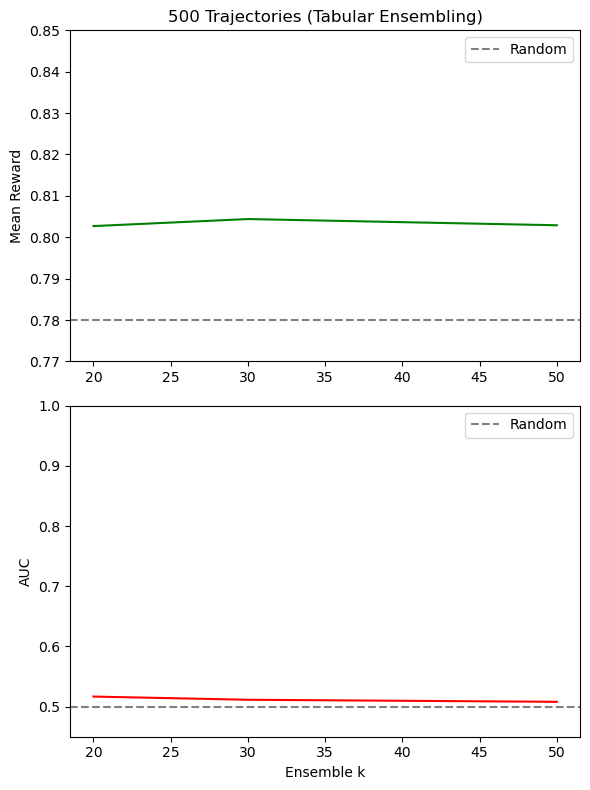

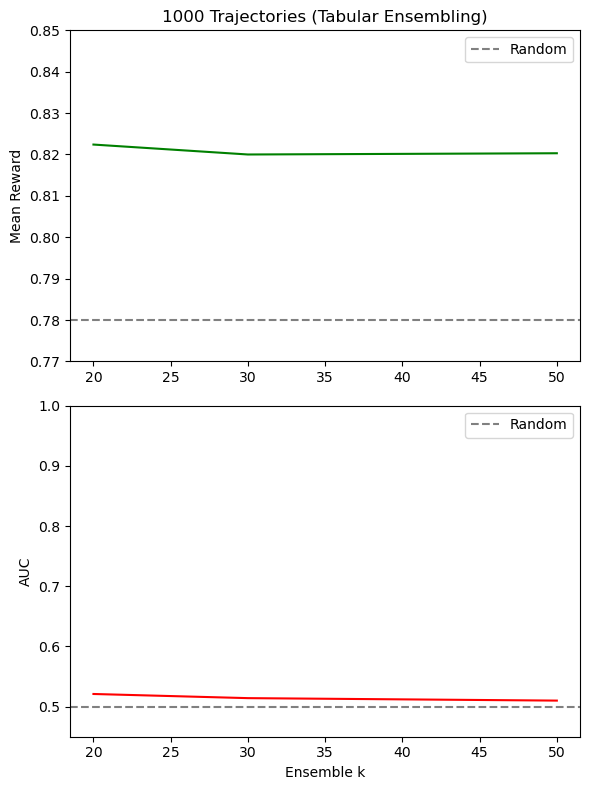

In [37]:
# Plot reward vs input (ensemble k or perturbation std or epsilon) for particular n. trajs
n_trajs = df_clean["N. Trajectories"].unique()

k = 50
epsilon = 3000

inpt = "Ensemble k"
context = "Tabular Ensembling"

for n_traj in n_trajs:
    #group = df_clean[(df_clean["N. Trajectories"] == n_traj) & (df_clean["Ensemble k"] == k)]
    group = df_clean[(df_clean["N. Trajectories"] == n_traj) & (df_clean["Ensemble epsilon"] == epsilon)]
    #group = df_clean[(df_clean["N. Trajectories"] == n_traj)]
    
    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(6, 8))
    
    # Rewards
    ax1.plot(group[inpt], group["Trainer Mean Reward (mean)"], color="green")
    ax1.set_ylim([0.77, 0.85])
    ax1.set_ylabel("Mean Reward")
    ax1.axhline(0.78, color="gray", linestyle="--", label="Random")
    ax1.set_title(f"{n_traj} Trajectories ({context})")
    ax1.legend()
    
    # Rewards
    ax2.plot(group[inpt], group["AUC (mean)"], color="red")
    ax2.set_ylim([0.45, 1.0])
    ax2.set_xlabel(inpt)
    ax2.set_ylabel("AUC")
    ax2.axhline(0.5, color="gray", linestyle="--", label="Random")
    ax2.legend()

    plt.tight_layout()
    plt.show()

    

In [36]:
import numpy as np
np.clip(-1,0,1).item()

0